Question 1: IQR-Based Outlier Detection in Sales Data

An e-commerce company wants to identify unusual transactions that may represent errors or unusually large purchases.
import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Transaction_ID": range(1, 13),
    "Sales": [120, 150, 180, 200, 220, 240,
              260, 280, 300, 350, 400, 2500],
    "Quantity": [1, 2, 2, 3, 3, 4,
                 4, 5, 5, 6, 7, 40]
})
svg
A. Implement the IQR method separately for Sales and Quantity. Calculate Q1, Q3, IQR, lower bounds, and upper bounds. Identify the outlier records and display the results in a new DataFrame containing the original values and outlier flags.

B. Visualize both features using boxplots. Create a filtered dataset excluding records identified as outliers in either feature. Compare the original and filtered means, medians, and standard deviations, and explain why removing an unusual transaction may or may not be appropriate.

Original DataFrame:
    Transaction_ID  Sales  Quantity
0                1    120         1
1                2    150         2
2                3    180         2
3                4    200         3
4                5    220         3
5                6    240         4
6                7    260         4
7                8    280         5
8                9    300         5
9               10    350         6
10              11    400         7
11              12   2500        40

Sales IQR Calculation:
Q1: 195.0
Q3: 312.5
IQR: 117.5
Lower Bound: 18.75
Upper Bound: 488.75

Quantity IQR Calculation:
Q1: 2.75
Q3: 5.25
IQR: 2.5
Lower Bound: -1.0
Upper Bound: 9.0

Outlier Detection Results:
    Transaction_ID  Sales  Quantity  Sales_Outlier  Quantity_Outlier
0                1    120         1          False             False
1                2    150         2          False             False
2                3    180         2          False             False
3                4    200

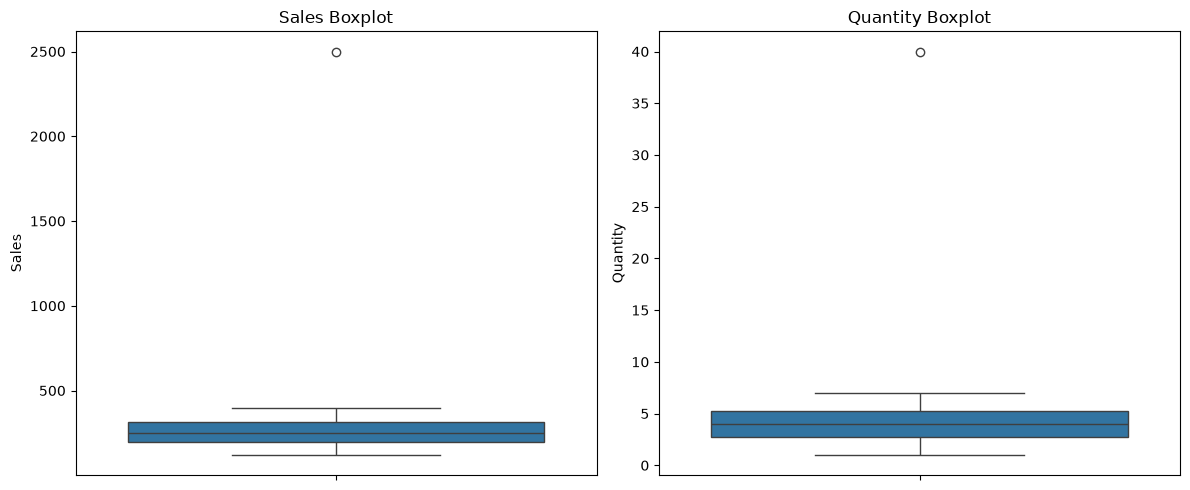


Filtered Dataset:
    Transaction_ID  Sales  Quantity  Sales_Outlier  Quantity_Outlier
0                1    120         1          False             False
1                2    150         2          False             False
2                3    180         2          False             False
3                4    200         3          False             False
4                5    220         3          False             False
5                6    240         4          False             False
6                7    260         4          False             False
7                8    280         5          False             False
8                9    300         5          False             False
9               10    350         6          False             False
10              11    400         7          False             False

Original Statistics:
         Sales  Quantity
mean    433.33      6.83
median  250.00      4.00
std     655.78     10.59

Filtered Statistics:
         

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.DataFrame({
    "Transaction_ID": range(1, 13),
    "Sales": [120, 150, 180, 200, 220, 240,
              260, 280, 300, 350, 400, 2500],
    "Quantity": [1, 2, 2, 3, 3, 4,
                 4, 5, 5, 6, 7, 40]
})

print("Original DataFrame:")
print(df)

# =====================================
# PART A: IQR OUTLIER DETECTION
# =====================================

features = ["Sales", "Quantity"]
outlier_info = {}

for column in features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_info[column] = {
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound
    }

    print(f"\n{column} IQR Calculation:")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)

    df[column + "_Outlier"] = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

print("\nOutlier Detection Results:")
print(df)

outliers = df[
    df["Sales_Outlier"] | df["Quantity_Outlier"]
]

print("\nOutlier Records:")
print(outliers)

# =====================================
# PART B: BOXPLOTS
# =====================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["Sales"], ax=axes[0])
axes[0].set_title("Sales Boxplot")

sns.boxplot(y=df["Quantity"], ax=axes[1])
axes[1].set_title("Quantity Boxplot")

plt.tight_layout()
plt.show()

filtered_df = df[
    ~(df["Sales_Outlier"] | df["Quantity_Outlier"])
].copy()

print("\nFiltered Dataset:")
print(filtered_df)

original_stats = df[features].agg(
    ["mean", "median", "std"]
)

filtered_stats = filtered_df[features].agg(
    ["mean", "median", "std"]
)

print("\nOriginal Statistics:")
print(original_stats.round(2))

print("\nFiltered Statistics:")
print(filtered_stats.round(2))

comparison = pd.concat(
    {
        "Original": original_stats,
        "Filtered": filtered_stats
    },
    axis=1
)

print("\nOriginal vs Filtered Comparison:")
print(comparison.round(2))


Question 2: Z-Score Detection and Statistical Interpretation
A manufacturing company measures the operating temperature of its machines. The engineering team suspects that some observations are unusually far from the average.

import numpy as np
import pandas as pd

df = pd.DataFrame({
    "Machine_ID": range(1, 13),
    "Temperature": [68, 70, 69, 72, 71, 73,
                    70, 74, 68, 72, 71, 115],
    "Pressure": [30, 32, 31, 33, 32, 34,
                 31, 33, 32, 35, 34, 60]
})
A. Calculate the Z-score for each observation in Temperature and Pressure using scipy.stats.zscore. Flag values whose absolute Z-score exceeds 3, display the results, and visualize the scores with scatterplots and horizontal threshold lines.

B. Repeat the analysis using thresholds of 2 and 3. Compare the number of flagged observations and explain how changing the threshold affects sensitivity to unusual values. Discuss why an extreme value can distort the mean and standard deviation used by the Z-score method.

Original DataFrame:
    Machine_ID  Temperature  Pressure
0            1           68        30
1            2           70        32
2            3           69        31
3            4           72        33
4            5           71        32
5            6           73        34
6            7           70        31
7            8           74        33
8            9           68        32
9           10           72        35
10          11           71        34
11          12          115        60

Z-Score Results:
    Machine_ID  Temperature  Pressure  Temperature_Zscore  \
0            1           68        30              -0.519   
1            2           70        32              -0.357   
2            3           69        31              -0.438   
3            4           72        33              -0.195   
4            5           71        32              -0.276   
5            6           73        34              -0.115   
6            7           70        31    

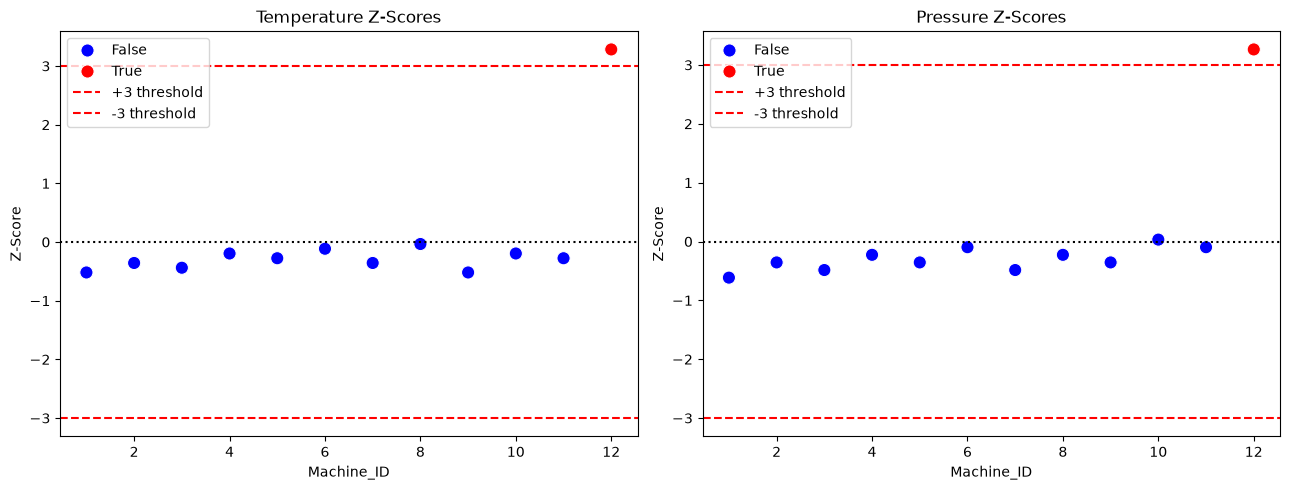


Threshold Comparison:
    Feature  Threshold  Flagged_Count Machine_IDs
Temperature          2              1        [12]
Temperature          3              1        [12]
   Pressure          2              1        [12]
   Pressure          3              1        [12]


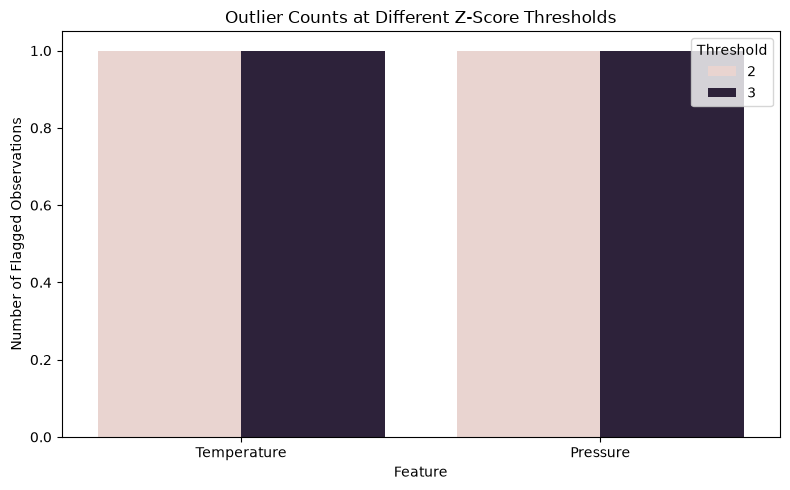


Outliers at Threshold 2:

Temperature:
    Machine_ID  Temperature  Temperature_Zscore
11          12          115               3.282

Pressure:
    Machine_ID  Pressure  Pressure_Zscore
11          12        60            3.264


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.DataFrame({
    "Machine_ID": range(1, 13),
    "Temperature": [68, 70, 69, 72, 71, 73,
                    70, 74, 68, 72, 71, 115],
    "Pressure": [30, 32, 31, 33, 32, 34,
                 31, 33, 32, 35, 34, 60]
})

print("Original DataFrame:")
print(df)

features = ["Temperature", "Pressure"]

#part A

for column in features:
    df[column + "_Zscore"] = stats.zscore(df[column])
    df[column + "_Outlier"] = (
        df[column + "_Zscore"].abs() > 3
    )

print("\nZ-Score Results:")
print(df.round(3))
print("\nOutliers at Threshold 3:")
for column in features:
    print(f"\n{column}:")
    print(
        df.loc[
            df[column + "_Outlier"],
            ["Machine_ID", column, column + "_Zscore"]
        ].round(3)
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, column in zip(axes, features):
    z_col = column + "_Zscore"

    sns.scatterplot(
        data=df,
        x="Machine_ID",
        y=z_col,
        hue=column + "_Outlier",
        palette={True: "red", False: "blue"},
        s=90,
        ax=ax
    )

    ax.axhline(3, color="red", linestyle="--",
               label="+3 threshold")
    ax.axhline(-3, color="red", linestyle="--",
               label="-3 threshold")
    ax.axhline(0, color="black", linestyle=":")

    ax.set_title(f"{column} Z-Scores")
    ax.set_ylabel("Z-Score")
    ax.legend()

plt.tight_layout()
plt.show()

# PART B

threshold_results = []

for column in features:
    z_col = column + "_Zscore"

    for threshold in [2, 3]:
        flag = df[z_col].abs() > threshold

        threshold_results.append({
            "Feature": column,
            "Threshold": threshold,
            "Flagged_Count": int(flag.sum()),
            "Machine_IDs": df.loc[flag, "Machine_ID"].tolist()
        })

threshold_df = pd.DataFrame(threshold_results)

print("\nThreshold Comparison:")
print(threshold_df.to_string(index=False))
plt.figure(figsize=(8, 5))

sns.barplot(
    data=threshold_df,
    x="Feature",
    y="Flagged_Count",
    hue="Threshold"
)

plt.title("Outlier Counts at Different Z-Score Thresholds")
plt.ylabel("Number of Flagged Observations")
plt.tight_layout()
plt.show()
print("\nOutliers at Threshold 2:")
for column in features:
    flag = df[column + "_Zscore"].abs() > 2

    print(f"\n{column}:")
    print(
        df.loc[
            flag,
            ["Machine_ID", column, column + "_Zscore"]
        ].round(3)
    )


Question 3: Comparing IQR and Z-Score on Skewed Data
A financial analyst is investigating transaction amounts. Most transactions are small, but a few are exceptionally large.

import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Transaction_Amount": [
        100, 120, 130, 150, 160, 170,
        180, 200, 220, 250, 300, 350,
        400, 450, 500, 800, 1200, 10000
    ]
})
A. Detect outliers using both the IQR method and the Z-score method with a threshold of 3. Create a comparison table showing each transaction's value, Z-score, IQR flag, and Z-score flag. Identify records detected by one method but not the other.

B. Plot the original transaction distribution and a boxplot. Explain why the methods can produce different results when data is strongly right-skewed. Based on the dataset, recommend a suitable detection method and justify your choice using the computed results.

Comparison Table:
 Transaction_Amount  Z_Score  IQR_Flag  Z_Score_Flag
                100   -0.346     False         False
                120   -0.337     False         False
                130   -0.332     False         False
                150   -0.323     False         False
                160   -0.319     False         False
                170   -0.314     False         False
                180   -0.310     False         False
                200   -0.301     False         False
                220   -0.292     False         False
                250   -0.278     False         False
                300   -0.256     False         False
                350   -0.234     False         False
                400   -0.211     False         False
                450   -0.189     False         False
                500   -0.166     False         False
                800   -0.032     False         False
               1200    0.147      True         False
              10000    4.093

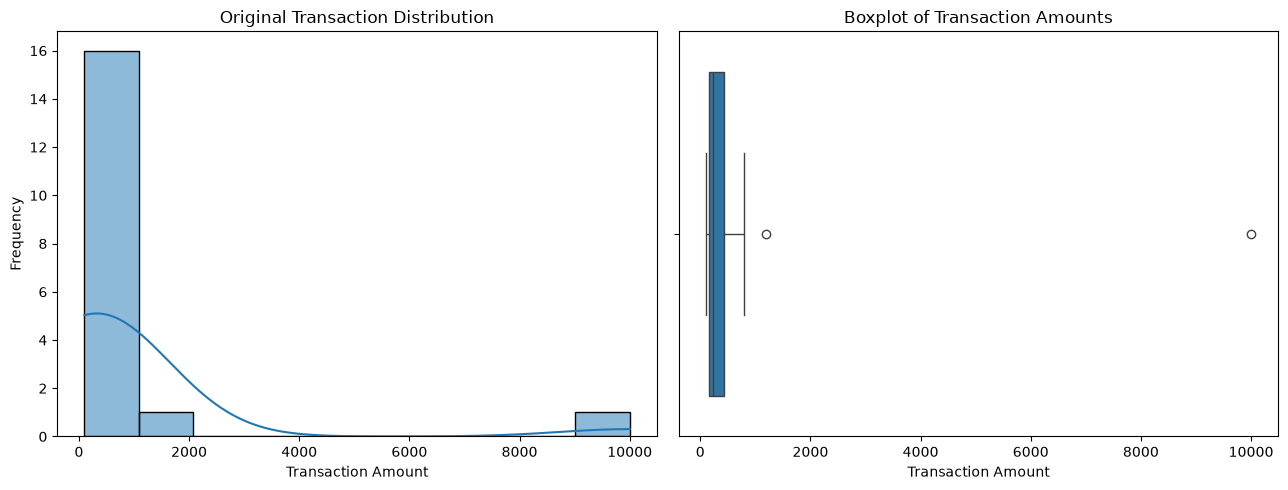

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.DataFrame({
    "Transaction_Amount": [
        100, 120, 130, 150, 160, 170,
        180, 200, 220, 250, 300, 350,
        400, 450, 500, 800, 1200, 10000
    ]
})
mean_value = df["Transaction_Amount"].mean()
std_value = df["Transaction_Amount"].std(ddof=0)

df["Z_Score"] = (
    (df["Transaction_Amount"] - mean_value) / std_value
)

Q1 = df["Transaction_Amount"].quantile(0.25)
Q3 = df["Transaction_Amount"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
df["IQR_Flag"] = (
    (df["Transaction_Amount"] < lower_limit) |
    (df["Transaction_Amount"] > upper_limit)
)

df["Z_Score_Flag"] = abs(df["Z_Score"]) > 3
print("Comparison Table:")
print(df.round(3).to_string(index=False))

iqr_only = df[
    df["IQR_Flag"] & ~df["Z_Score_Flag"]
]

zscore_only = df[
    df["Z_Score_Flag"] & ~df["IQR_Flag"]
]

print("\nOutliers detected by IQR only:")
print(iqr_only[["Transaction_Amount", "Z_Score"]].round(3))

print("\nOutliers detected by Z-score only:")
print(zscore_only[["Transaction_Amount", "Z_Score"]].round(3))

print("\nMean:", round(mean_value, 2))
print("Standard Deviation:", round(std_value, 2))
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

print("\nIQR outlier count:", df["IQR_Flag"].sum())
print("Z-score outlier count:", df["Z_Score_Flag"].sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=df,
    x="Transaction_Amount",
    bins=10,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Original Transaction Distribution")
axes[0].set_xlabel("Transaction Amount")
axes[0].set_ylabel("Frequency")

sns.boxplot(
    data=df,
    x="Transaction_Amount",
    ax=axes[1]
)
axes[1].set_title("Boxplot of Transaction Amounts")
axes[1].set_xlabel("Transaction Amount")

plt.tight_layout()
plt.show()


Question 4: Outlier Detection in Student Performance
An educational institution wants to analyze student study hours and exam scores to identify unusual records and understand their potential effect on summary statistics.

import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Student_ID": range(1, 13),
    "Study_Hours": [1, 2, 2, 3, 3, 4,
                    4, 5, 5, 6, 7, 50],
    "Exam_Score": [35, 40, 45, 48, 52, 55,
                   60, 65, 68, 72, 78, 100]
})
A. Apply the IQR and Z-score methods to both features. Produce a DataFrame that marks each student as an outlier or non-outlier under each method. Visualize the feature distributions with boxplots and create a scatterplot of study hours against exam scores.

B. Calculate the correlation between study hours and exam scores before and after removing records flagged by at least one method. Compare the results and explain why removing an observation can change the correlation without proving that the observation was incorrect.

Outlier Detection Results:
 Student_ID  Study_Hours  Exam_Score  Study_Hours_IQR_Outlier  Study_Hours_Z_Outlier  Exam_Score_IQR_Outlier  Exam_Score_Z_Outlier
          1            1          35                    False                  False                   False                 False
          2            2          40                    False                  False                   False                 False
          3            2          45                    False                  False                   False                 False
          4            3          48                    False                  False                   False                 False
          5            3          52                    False                  False                   False                 False
          6            4          55                    False                  False                   False                 False
          7            4          60                    

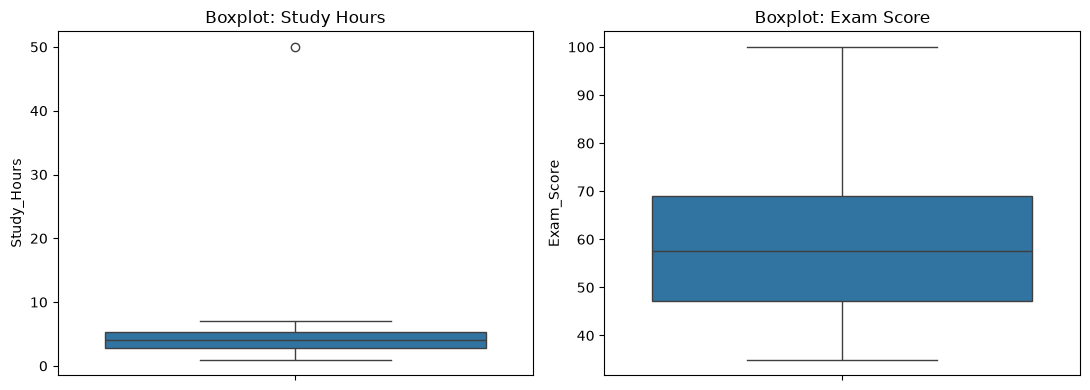

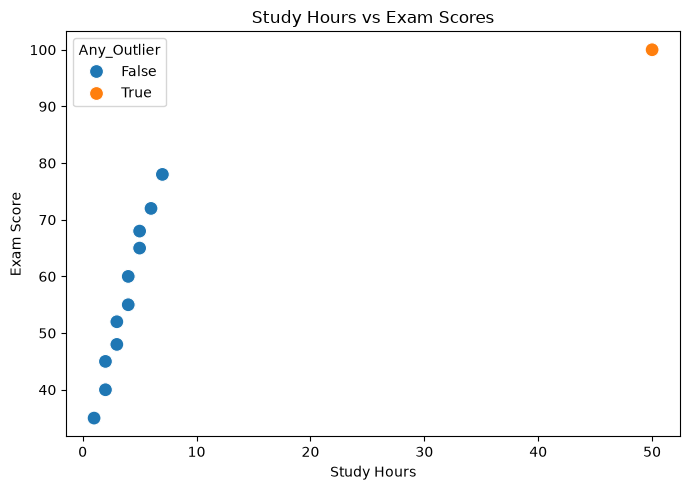


Correlation before removing outliers: 0.7818
Correlation after removing flagged records: 0.9877

Number of original records: 12
Number of remaining records: 11


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Student_ID": range(1, 13),
    "Study_Hours": [1, 2, 2, 3, 3, 4,
                    4, 5, 5, 6, 7, 50],
    "Exam_Score": [35, 40, 45, 48, 52, 55,
                   60, 65, 68, 72, 78, 100]
})

for col in ["Study_Hours", "Exam_Score"]:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col + "_IQR_Outlier"] = (
        (df[col] < lower) | (df[col] > upper)
    )

    z_score = (
        (df[col] - df[col].mean()) /
        df[col].std(ddof=0)
    )

    df[col + "_Z_Outlier"] = abs(z_score) > 3

print("Outlier Detection Results:")
print(df.to_string(index=False))

df["Any_Outlier"] = (
    df["Study_Hours_IQR_Outlier"] |
    df["Study_Hours_Z_Outlier"] |
    df["Exam_Score_IQR_Outlier"] |
    df["Exam_Score_Z_Outlier"]
)

print("\nStudents flagged as outliers:")
print(df.loc[df["Any_Outlier"],
             ["Student_ID", "Study_Hours", "Exam_Score"]])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(y=df["Study_Hours"], ax=axes[0])
axes[0].set_title("Boxplot: Study Hours")

sns.boxplot(y=df["Exam_Score"], ax=axes[1])
axes[1].set_title("Boxplot: Exam Score")

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="Exam_Score",
    hue="Any_Outlier",
    s=100
)
plt.title("Study Hours vs Exam Scores")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.tight_layout()
plt.show()

original_corr = df["Study_Hours"].corr(df["Exam_Score"])

clean_df = df.loc[~df["Any_Outlier"]].copy()

new_corr = clean_df["Study_Hours"].corr(
    clean_df["Exam_Score"]
)

print("\nCorrelation before removing outliers:",
      round(original_corr, 4))

print("Correlation after removing flagged records:",
      round(new_corr, 4))

print("\nNumber of original records:", len(df))
print("Number of remaining records:", len(clean_df))
